## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Marin Marcillac

**Date:** 10/12/2026

In [1]:
import numpy as np
import pandas as pd
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

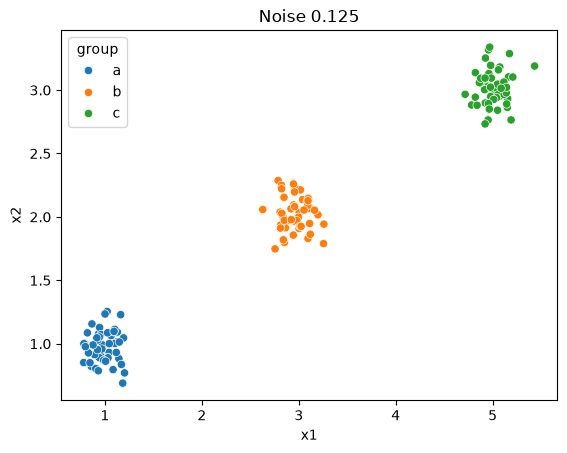

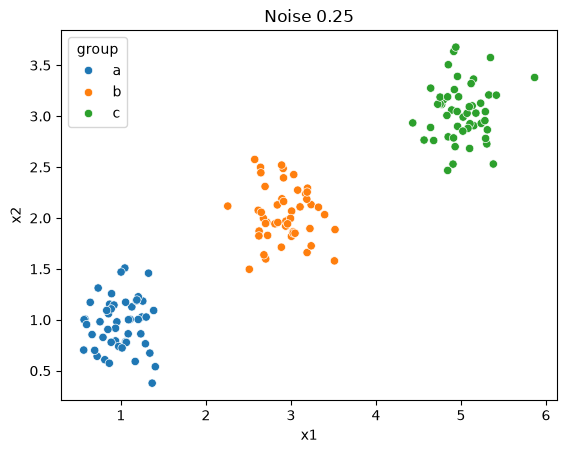

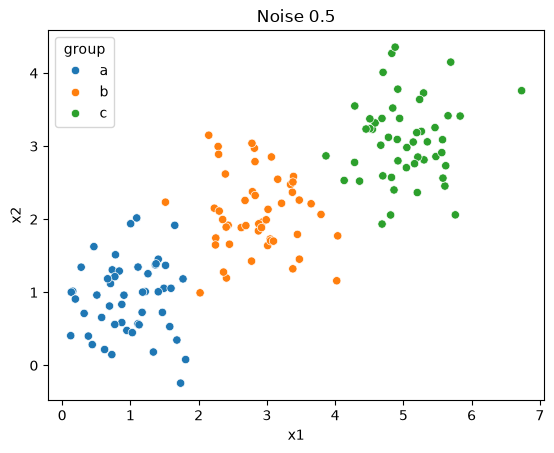

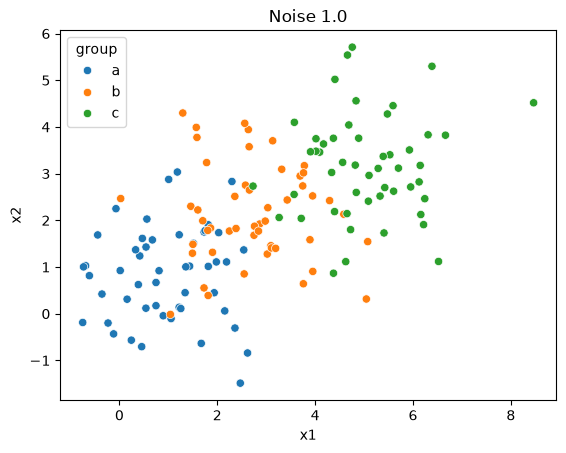

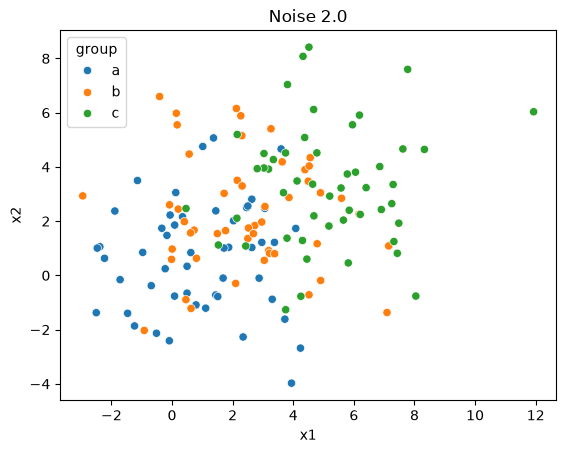

In [2]:
import seaborn as sns 
import matplotlib.pyplot as plt


sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group").set(title="Noise 0.125")
plt.show()
sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group").set(title="Noise 0.25")
plt.show()
sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group").set(title="Noise 0.5")
plt.show()
sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group").set(title="Noise 1.0")
plt.show()
sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group").set(title="Noise 2.0")
plt.show()

Question 1: As the noise increases from 0.125 to 2.0, the cluster spread out and increasignly overlap each other. At a noise level of 0.125, there are three perfectly distict, tightly packed clusters. As the noise increases to 0.5, the edjetives the clusters begin to touch each other. By the time thae noise reaches 2.0, the points are scattered that there is no telling what the distict groups are becuase it looks like a big clouds. 

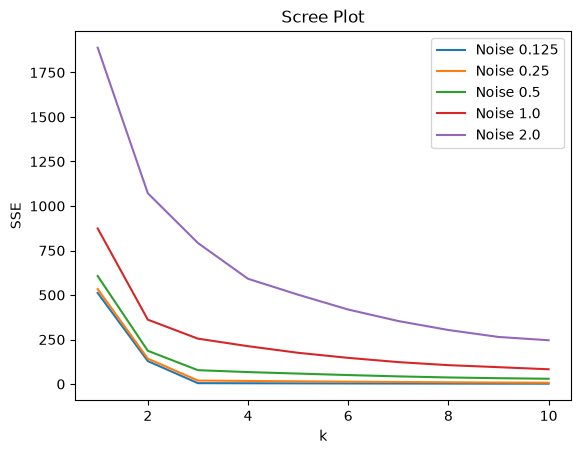

In [3]:

#my loop wasnt working and dont know why so I just used this hopefully Ai can help and make me the right loop
from sklearn.cluster import KMeans
ks = np.arange(1, 11)

SSE_0_125 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df0_125[["x1", "x2"]]).inertia_ for k in ks]
SSE_0_25 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df0_25[["x1", "x2"]]).inertia_ for k in ks]
SSE_0_5 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df0_5[["x1", "x2"]]).inertia_ for k in ks]
SSE_1_0 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df1_0[["x1", "x2"]]).inertia_ for k in ks]
SSE_2_0 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df2_0[["x1", "x2"]]).inertia_ for k in ks]


sns.lineplot(x=ks, y=SSE_0_125, label="Noise 0.125")
sns.lineplot(x=ks, y=SSE_0_25, label="Noise 0.25")
sns.lineplot(x=ks, y=SSE_0_5, label="Noise 0.5")
sns.lineplot(x=ks, y=SSE_1_0, label="Noise 1.0")
sns.lineplot(x=ks, y=SSE_2_0, label="Noise 2.0").set(title="Scree Plot", xlabel="k", ylabel="SSE")

plt.show()

#Increasing the noise level affects the scree plot in two ways. There is a higher overall error in in which the sse curve is signifally higher because the points are farther away from their cluster centers. 
#At low noise levels there is a sharp distict elbow at k=3 so it make it easy to choose the correct number of cluster. 
#When the nouse increases to 1.0 and 2,0, the sharp bend becomes more gradual and with high noise, 
#the SSE decreases without super big endges so it makes it extremly difficult to confiednelty select the right k value.
#SSE measures are tightly packed the cluster are. 

In [6]:
 

#The elbow helps us figure out the best k value by showing exactly where the algorithm stops finding real groups and starts just fitting random noise. 
#For the low noise datasets, the algorithm easily spots the three distinct clumps. 
#Moving from k=1 to k=2 and then to k=3 causes steep drops in the SSE because the algorithm is successfully identifying those separate groups. 
#However, once k goes above 3, the line suddenly flattens out.. With the high noise datasets,
#those distinct clumps have basically merged into one giant cloud.
#Because the noise is so high, increasing k just randomly slices up this massive blob without actually separating real groups. Since it never locks onto clear clusters, 
#the SSE just drops at a slow rate and we never get that clear "elbow" shape.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans


In [8]:
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df_2020 = df.loc[df["Year"] == 2020].dropna().copy()
print("Number of countries")
print(len(df_2020))
#Answer:Yes, further cleaning should be done. I did get 148 countries, but there are probably 
#extreme outliers (like the United States) that will skew the results because we are using max-min normalization.

Number of countries
148


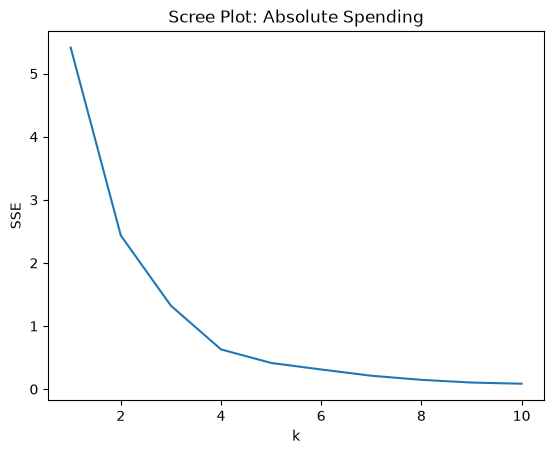

In [9]:
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df_2020.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X2 = (unscaled - mins) / ranges

ks = np.arange(1, 11)
SSE2 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X2).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE2).set(title="Scree Plot: Absolute Spending", xlabel="k", ylabel="SSE")
plt.show()

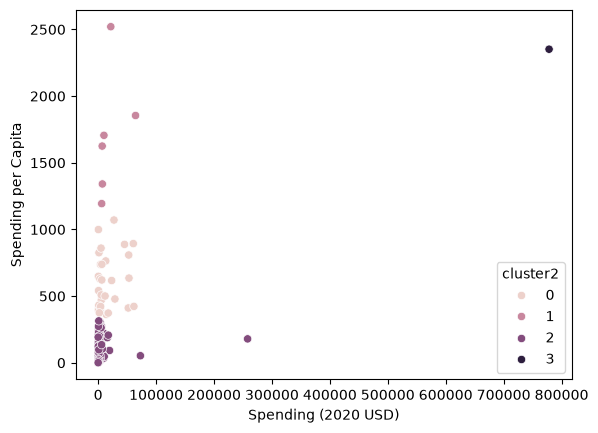

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                       30.0   17077.591354  20583.053357     405.790494   
1                        6.0   19443.362047  22861.507114    6095.708713   
2                      111.0    4859.185065  25405.739131       8.622460   
3                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0           2294.039665    5857.060906   26296.001003   61712.537169   
1           7023.251766    8624.225729   18857.070183   64558.400000   
2            130.010211     382.464677    2297.032353  257973.429834   
3         778397.200000  778397.200

In [10]:
model2 = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(X2)
df_2020["cluster2"] = model2.labels_
sns.scatterplot(data=df_2020, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster2")
plt.show()
print(df_2020.groupby("cluster2")[features].describe())

In [19]:
#Looking at the describe table, I see that the algorithm split the data into one massive group,
#two middle groups, and one extreme outlier. The United States is in Cluster 3 entirely by itself. 
#I can tell because the count for that cluster is exactly 1, and the absolute spending is $778 billion. 
#The main pattern I notice is that cluster is driven by extreme differences in wealth and country size. 
#The  majority of the world (111 countries) gets lumped together into a single low-spending group,
#while the country like US is so large that the algorithm is forced to isolate it.


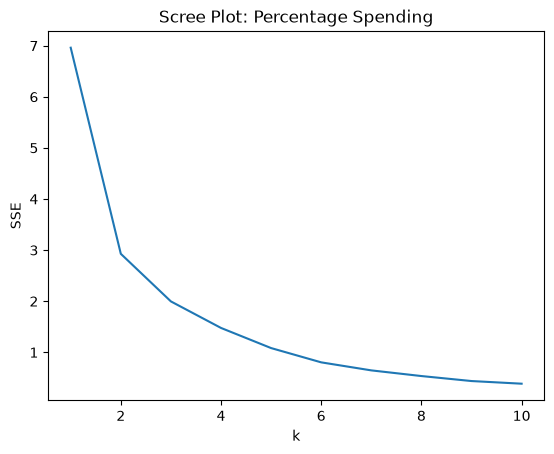

In [12]:
features3 = ["Percent of Government Spending", "Percent of GDP"]
unscaled3 = df_2020.loc[:, features3]
mins3 = unscaled3.min()
ranges3 = unscaled3.max() - mins3
X3 = (unscaled3 - mins3) / ranges3

SSE3 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X3).inertia_ 
    for k in ks
]
sns.lineplot(x=ks, y=SSE3).set(title="Scree Plot: Percentage Spending", xlabel="k", ylabel="SSE")
plt.show()


#For the percentage variables, I chose k=3 based on the elbow of my scree plot. The clusters are more balanced. 
#Because percentages normalize for a country's size and total wealth, the algorithm stops grouping countries by economic dominance. 
#Instead, it groups them by how heavily they prioritize the military. 
#This means smaller but highly militarized nations form the top clusters so 
#rather than just the the superpowers.


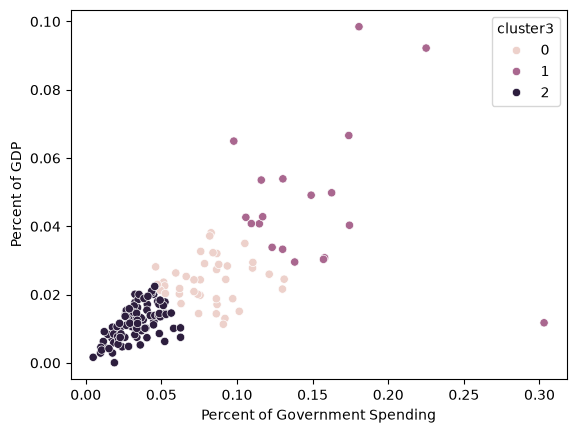

In [13]:
model3 = KMeans(n_clusters=3, n_init="auto", random_state=0).fit(X3)
df_2020["cluster3"] = model3.labels_

sns.scatterplot(data=df_2020, x="Percent of Government Spending", y="Percent of GDP", hue="cluster3")
plt.show()




In [14]:
print(df_2020.groupby("cluster3")[features3].describe())

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  40.0  0.081391  0.021601  0.046211   
1                                  19.0  0.150875  0.048785  0.097882   
2                                  89.0  0.033497  0.013242  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.065564  0.082430  0.092176  0.131184           40.0  0.023924   
1         0.116521  0.138143  0.168248  0.303027           19.0  0.047657   
2         0.023300  0.033620  0.043645  0.062685           89.0  0.011698   

                                                                      
               std       mi

In [15]:
#When using all four variables, I chose k=4clusters. The algorithm still isolates the massive absolute spenders like the United States into their own tiny cluster 
#but it does a much better job of separating the rest of the world.
# Instead of puting 111 countries into a single low-spending group like in Part 2, 
#it uses the percentage variables to split those smaller countries based on their relative economic burden.


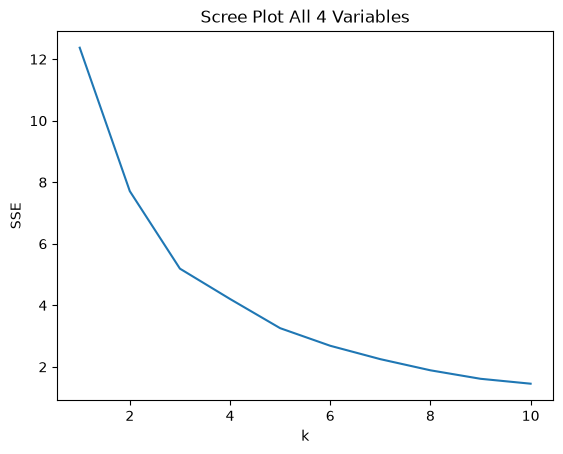

In [16]:

features4 = [
    "Spending (2020 USD)", "Spending per Capita", 
    "Percent of Government Spending", "Percent of GDP"
]
unscaled4 = df_2020.loc[:, features4]
mins4 = unscaled4.min()
ranges4 = unscaled4.max() - mins4
X4 = (unscaled4 - mins4) / ranges4


SSE4 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X4).inertia_ 
    for k in ks
]
sns.lineplot(x=ks, y=SSE4).set(title="Scree Plot All 4 Variables", xlabel="k", ylabel="SSE")
plt.show()




In [17]:
model4 = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(X4)
df_2020["cluster4"] = model4.labels_


print(df_2020.groupby("cluster4")[features4].describe())

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        2.0   35327.054356   41339.365456  6095.708713   
2                        4.0  204283.345885  382796.365368  6941.042345   
3                      111.0    7086.472777   26479.379918     8.622460   

                                                                    \
                   25%           50%            75%            max   
cluster4                                                             
0           467.787851   1404.787234    7739.166193   72937.064048   
1         20711.381534  35327.054356   49942.727178   64558.400000   
2          9219.189158  15897.570598  210961.727326  778397.200000   
3           130.010211    567.650747    3910.107493  2

In [18]:
#Yes, the k-means algorithm found very useful patterns. Clustering by absolute dollars just grouped the wealthiest countries together, 
#while clustering by percentages showed the actual economic burden on smaller countries. #Using all four variables at once was the most useful because it gave the best of both worlds
# it captured the massive scale of the superpowers
# while still showing the real economic impact on every country.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]